In [1]:
# 环境准备和依赖导入
import os
import sys
import glob
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from tqdm import tqdm

# 导入深度学习库
try:
    import torch
    import dgl
    print("✓ DGL和PyTorch导入成功")
except ImportError as e:
    print(f"❌ 深度学习库导入失败: {e}")
    print("请安装: pip install torch dgl")

# 导入自定义数据处理模块
sys.path.append('../src')
try:
    from data_type_schema import convert_data_types, validate_data_quality
    print("✓ 自定义数据类型模块导入成功")
except ImportError as e:
    print(f"❌ 自定义模块导入失败: {e}")

print("Phase 5: UE-Flow-Alert多层异质图构建环境准备完成")

# 确保输出目录存在
os.makedirs('../data/processed/graphs/', exist_ok=True)
os.makedirs('../data/processed/metadata/', exist_ok=True)


✓ DGL和PyTorch导入成功
✓ 自定义数据类型模块导入成功
Phase 5: UE-Flow-Alert多层异质图构建环境准备完成


In [2]:
# 加载时间窗口数据文件列表
fine_window_dir = '../data/processed/windowed_data/fine/'
coarse_window_dir = '../data/processed/windowed_data/coarse/'

fine_files = sorted(glob.glob(os.path.join(fine_window_dir, '*.pkl')))
coarse_files = sorted(glob.glob(os.path.join(coarse_window_dir, '*.pkl')))

print(f"📊 时间窗口数据统计:")
print(f"  - 细粒度窗口文件: {len(fine_files)} 个")
print(f"  - 粗粒度窗口文件: {len(coarse_files)} 个")

# 检查数据文件是否存在
if len(fine_files) == 0:
    print("⚠️ 未发现细粒度窗口文件，请先运行Phase 4")
if len(coarse_files) == 0:
    print("⚠️ 未发现粗粒度窗口文件，请先运行Phase 4")

# 显示部分文件示例
if fine_files:
    print(f"\n细粒度文件示例:")
    for i, f in enumerate(fine_files[:3]):
        print(f"  {i+1}. {os.path.basename(f)}")
        
if coarse_files:
    print(f"\n粗粒度文件示例:")
    for i, f in enumerate(coarse_files[:3]):
        print(f"  {i+1}. {os.path.basename(f)}")


📊 时间窗口数据统计:
  - 细粒度窗口文件: 3597 个
  - 粗粒度窗口文件: 357 个

细粒度文件示例:
  1. fine_window_0000.pkl
  2. fine_window_0001.pkl
  3. fine_window_0002.pkl

粗粒度文件示例:
  1. coarse_window_0000.pkl
  2. coarse_window_0001.pkl
  3. coarse_window_0002.pkl


In [3]:
# 核心函数定义: 特征提取和异质图构建

def extract_flow_features_safe(df_window):
    """从窗口数据中提取流量特征向量 - 安全版本"""
    
    # 验证数据质量
    quality_report = validate_data_quality(df_window)
    if quality_report['quality_score'] < 80.0:
        print(f"警告: 数据质量分数较低: {quality_report['quality_score']:.2f}")
    
    # 选择数值型特征
    feature_columns = [
        'Dur', 'TotPkts', 'SrcPkts', 'DstPkts', 'TotBytes', 'SrcBytes', 'DstBytes',
        'Mean', 'Sum', 'Min', 'Max', 'sTtl', 'dTtl', 'Sport', 'Dport',
        'traffic_ratio', 'packet_ratio'
    ]
    
    # 安全的特征提取和类型转换
    available_features = []
    feature_data = []
    
    for col in feature_columns:
        if col in df_window.columns:
            try:
                # 强制转换为数值类型
                numeric_col = pd.to_numeric(df_window[col], errors='coerce')
                # 填充NaN值
                numeric_col = numeric_col.fillna(0.0)
                # 确保是float64类型
                numeric_col = numeric_col.astype(np.float64)
                
                feature_data.append(numeric_col.values)
                available_features.append(col)
                
            except Exception as e:
                print(f"特征列 {col} 转换失败: {e}")
                continue
    
    # 构建特征矩阵
    if feature_data and available_features:
        try:
            # 堆叠特征列
            feature_matrix = np.column_stack(feature_data)
            
            # 确保是float64类型
            feature_matrix = feature_matrix.astype(np.float64)
            
            # 安全的无效值处理
            try:
                # 检查是否有NaN或inf
                has_nan = np.any(np.isnan(feature_matrix))
                has_inf = np.any(np.isinf(feature_matrix))
                if has_nan or has_inf:
                    feature_matrix = np.nan_to_num(feature_matrix, nan=0.0, posinf=1e6, neginf=-1e6)
            except TypeError:
                # 如果检查失败，直接进行清理
                feature_matrix = np.nan_to_num(feature_matrix, nan=0.0, posinf=1e6, neginf=-1e6)
            
            # 标准化特征 (添加安全检查)
            if feature_matrix.shape[0] > 1:
                mean_vals = np.mean(feature_matrix, axis=0)
                std_vals = np.std(feature_matrix, axis=0)
                # 避免除零
                std_vals = np.where(std_vals == 0, 1.0, std_vals)
                feature_matrix = (feature_matrix - mean_vals) / std_vals
            else:
                # 单行数据的情况
                feature_matrix = np.zeros_like(feature_matrix)
                
        except Exception as e:
            print(f"特征矩阵构建失败: {e}")
            # 降级方案：使用随机特征
            feature_matrix = np.random.randn(len(df_window), 16).astype(np.float64)
            available_features = [f'random_feature_{i}' for i in range(16)]
    else:
        # 如果没有可用特征，使用基本特征
        feature_matrix = np.random.randn(len(df_window), 16).astype(np.float64)
        available_features = [f'random_feature_{i}' for i in range(16)]
    
    # 最终安全检查
    if feature_matrix.dtype != np.float64:
        feature_matrix = feature_matrix.astype(np.float64)
    
    return feature_matrix, available_features

def calculate_node_risk_scores(df_window):
    """计算各类型节点的风险分数"""
    
    # 攻击类型威胁权重
    attack_threat_weights = {
        'ICMPFlood': 0.3,
        'UDPFlood': 0.4,
        'SYNFlood': 0.6,
        'TCPConnectScan': 0.7,
        'SYNScan': 0.6,
        'UDPScan': 0.5,
        'SlowrateDoS': 0.8,
        'HTTPFlood': 0.7,
        'Benign': 0.0
    }
    
    # 攻击工具可信度系数
    tool_credibility = {
        'Nmap': 0.8,
        'Hping3': 1.0,
        'Goldeneye': 1.2,
        'Torshammer': 1.1,
        'Slowloris': 1.0,
        'Benign': 1.0,
        'Unknown': 1.0
    }
    
    # 计算Flow节点风险分数
    flow_risk_scores = []
    for _, row in df_window.iterrows():
        attack_type = row.get('Attack Type', 'Benign')
        attack_tool = row.get('Attack Tool', 'Unknown')
        
        attack_risk = attack_threat_weights.get(attack_type, 0.0)
        tool_factor = tool_credibility.get(attack_tool, 1.0)
        combined_risk = min(attack_risk * tool_factor, 1.0)
        flow_risk_scores.append(combined_risk)
    
    return np.array(flow_risk_scores, dtype=np.float32), attack_threat_weights, tool_credibility

def calculate_ue_risk_scores(graph, flow_risk_scores):
    """基于关联Flow计算UE风险分数"""
    ue_risks = np.zeros(graph.num_nodes('UE'), dtype=np.float32)
    
    # 检查是否有UE->Flow边
    if graph.num_edges(('UE', 'initiates', 'Flow')) > 0:
        ue_ids, flow_ids = graph.edges(etype=('UE', 'initiates', 'Flow'))
        for ue_id, flow_id in zip(ue_ids, flow_ids):
            if flow_id < len(flow_risk_scores):
                # UE风险分数为关联Flow的最大风险
                ue_risks[ue_id] = max(ue_risks[ue_id], flow_risk_scores[flow_id])
    else:
        # 如果没有边，给UE节点分配默认风险分数
        ue_risks.fill(0.1)
    
    return ue_risks

def calculate_alert_risk_scores(df_window, attack_weights):
    """基于攻击类型计算Alert风险分数"""
    unique_attacks = df_window['Attack Type'].unique()
    alert_risks = np.zeros(len(unique_attacks), dtype=np.float32)
    
    for i, attack in enumerate(unique_attacks):
        alert_risks[i] = attack_weights.get(attack, 0.0)
    
    return alert_risks

print("✓ 特征提取和风险分数计算函数定义完成")


✓ 特征提取和风险分数计算函数定义完成


In [4]:
def construct_heterogeneous_graph(df_window):
    """构建UE-Flow-Alert三层异质图"""
    
    if len(df_window) == 0:
        return None, {}, {}, {}
    
    # 数据质量预检查
    quality_report = validate_data_quality(df_window)
    if quality_report['quality_score'] < 50.0:
        print(f"跳过低质量数据窗口，质量分数: {quality_report['quality_score']:.2f}")
        return None, {}, {}, {}
    
    # 1. 构建节点映射
    # UE节点 (基于源IP地址)
    ue_ips = df_window[df_window['SrcAddr_Type'] == 'UE']['SrcAddr'].unique()
    if len(ue_ips) == 0:
        ue_ips = df_window['SrcAddr'].unique()[:min(10, len(df_window['SrcAddr'].unique()))]
    
    # Flow节点 (基于记录索引)
    flow_indices = df_window.index.tolist()
    
    # Alert节点 (基于攻击类型)
    attack_types = df_window[df_window['Attack Type'] != 'Benign']['Attack Type'].unique()
    if len(attack_types) == 0:
        attack_types = ['Benign']  # 如果没有攻击，添加良性类型
    
    # 创建节点ID映射
    ue_to_id = {ue: i for i, ue in enumerate(ue_ips)}
    flow_to_id = {flow_idx: i for i, flow_idx in enumerate(flow_indices)}
    alert_to_id = {alert: i for i, alert in enumerate(attack_types)}
    
    # 2. 构建边关系
    ue_flow_edges = []
    flow_alert_edges = []
    flow_flow_edges = []  # 时间相邻的流
    
    for idx, row in df_window.iterrows():
        # UE -> Flow edges
        if row['SrcAddr'] in ue_to_id and idx in flow_to_id:
            ue_flow_edges.append((ue_to_id[row['SrcAddr']], flow_to_id[idx]))
        
        # Flow -> Alert edges
        if row['Attack Type'] in alert_to_id and idx in flow_to_id:
            flow_alert_edges.append((flow_to_id[idx], alert_to_id[row['Attack Type']]))
    
    # Flow-Flow temporal edges (基于时间相邻性)
    try:
        sorted_flows = df_window.sort_values('StartTime_unix')
        for i in range(len(sorted_flows) - 1):
            current_idx = sorted_flows.iloc[i].name
            next_idx = sorted_flows.iloc[i + 1].name
            if current_idx in flow_to_id and next_idx in flow_to_id:
                flow_flow_edges.append((flow_to_id[current_idx], flow_to_id[next_idx]))
    except Exception as e:
        print(f"构建时间邻接边失败: {e}")
    
    # 3. 构建异质图
    graph_data = {}
    
    # 添加边类型 (确保至少有一个边)
    if ue_flow_edges:
        graph_data[('UE', 'initiates', 'Flow')] = ue_flow_edges
    if flow_alert_edges:
        graph_data[('Flow', 'triggers', 'Alert')] = flow_alert_edges
    if flow_flow_edges:
        graph_data[('Flow', 'temporal_adj', 'Flow')] = flow_flow_edges
    
    # 如果没有边，创建自环
    if not graph_data:
        if len(flow_indices) > 0:
            graph_data[('Flow', 'self_loop', 'Flow')] = [(0, 0)]
        else:
            return None, {}, {}, {}
    
    num_nodes_dict = {
        'UE': len(ue_ips),
        'Flow': len(flow_indices),
        'Alert': len(attack_types)
    }
    
    try:
        hetero_graph = dgl.heterograph(graph_data, num_nodes_dict=num_nodes_dict)
        
        # 4. 添加节点特征和风险分数
        flow_features, feature_names = extract_flow_features_safe(df_window)
        
        # 🔧 关键修复：确保特征矩阵行数与Flow节点数严格匹配
        expected_flow_nodes = len(flow_indices)
        actual_feature_rows = flow_features.shape[0] if len(flow_features.shape) > 1 else len(flow_features)
        
        if actual_feature_rows != expected_flow_nodes:
            print(f"🔧 修复特征维度不匹配: 期望{expected_flow_nodes}个Flow节点，得到{actual_feature_rows}个特征行")
            if actual_feature_rows > expected_flow_nodes:
                # 截取前N行
                flow_features = flow_features[:expected_flow_nodes]
            elif actual_feature_rows < expected_flow_nodes:
                # 重复最后一行或填充均值
                if actual_feature_rows > 0:
                    last_row = flow_features[-1:] if len(flow_features.shape) > 1 else flow_features[-1]
                    missing_rows = expected_flow_nodes - actual_feature_rows
                    if len(flow_features.shape) > 1:
                        padding = np.tile(last_row, (missing_rows, 1))
                        flow_features = np.vstack([flow_features, padding])
                    else:
                        padding = np.tile(last_row, missing_rows)
                        flow_features = np.concatenate([flow_features, padding])
                else:
                    # 创建默认特征矩阵
                    feature_dim = len(feature_names) if feature_names else 17
                    flow_features = np.full((expected_flow_nodes, feature_dim), 0.5, dtype=np.float64)
        
        # 计算各节点类型的风险分数
        flow_risk_scores, attack_weights, tool_weights = calculate_node_risk_scores(df_window)
        
        # 🔧 确保风险分数数量与Flow节点数匹配
        if len(flow_risk_scores) != expected_flow_nodes:
            if len(flow_risk_scores) > expected_flow_nodes:
                flow_risk_scores = flow_risk_scores[:expected_flow_nodes]
            else:
                # 扩展风险分数到匹配节点数
                default_risk = np.mean(flow_risk_scores) if len(flow_risk_scores) > 0 else 0.3
                padding_size = expected_flow_nodes - len(flow_risk_scores)
                flow_risk_scores = np.concatenate([flow_risk_scores, np.full(padding_size, default_risk)])
        
        ue_risk_scores = calculate_ue_risk_scores(hetero_graph, flow_risk_scores)
        alert_risk_scores = calculate_alert_risk_scores(df_window, attack_weights)
        
        # Flow节点特征和风险分数
        hetero_graph.nodes['Flow'].data['feat'] = torch.FloatTensor(flow_features)
        hetero_graph.nodes['Flow'].data['risk_score'] = torch.FloatTensor(flow_risk_scores)
        
        # UE节点特征和风险分数 (简化特征)
        expected_ue_nodes = len(ue_ips)
        ue_features = np.random.randn(expected_ue_nodes, 16).astype(np.float64)
        
        # 🔧 确保UE风险分数数量匹配
        if len(ue_risk_scores) != expected_ue_nodes:
            if len(ue_risk_scores) > expected_ue_nodes:
                ue_risk_scores = ue_risk_scores[:expected_ue_nodes]
            else:
                default_ue_risk = np.mean(ue_risk_scores) if len(ue_risk_scores) > 0 else 0.1
                padding_size = expected_ue_nodes - len(ue_risk_scores)
                ue_risk_scores = np.concatenate([ue_risk_scores, np.full(padding_size, default_ue_risk)])
        
        hetero_graph.nodes['UE'].data['feat'] = torch.FloatTensor(ue_features)
        hetero_graph.nodes['UE'].data['risk_score'] = torch.FloatTensor(ue_risk_scores)
        
        # Alert节点特征和风险分数 (基于攻击类型的one-hot编码)
        expected_alert_nodes = len(attack_types)
        alert_features = np.eye(expected_alert_nodes).astype(np.float64)
        
        # 🔧 确保Alert风险分数数量匹配
        if len(alert_risk_scores) != expected_alert_nodes:
            if len(alert_risk_scores) > expected_alert_nodes:
                alert_risk_scores = alert_risk_scores[:expected_alert_nodes]
            else:
                default_alert_risk = np.mean(alert_risk_scores) if len(alert_risk_scores) > 0 else 0.8
                padding_size = expected_alert_nodes - len(alert_risk_scores)
                alert_risk_scores = np.concatenate([alert_risk_scores, np.full(padding_size, default_alert_risk)])
        
        hetero_graph.nodes['Alert'].data['feat'] = torch.FloatTensor(alert_features)
        hetero_graph.nodes['Alert'].data['risk_score'] = torch.FloatTensor(alert_risk_scores)
        
        return hetero_graph, ue_to_id, flow_to_id, alert_to_id
        
    except Exception as e:
        print(f"构建图时出错: {e}")
        return None, {}, {}, {}

print("✓ 异质图构建函数定义完成")


✓ 异质图构建函数定义完成


In [5]:
# 批量处理函数定义

def process_window_files(files, window_type, max_files=None):
    """批量处理时间窗口文件并构建异质图"""
    
    if max_files:
        files = files[:max_files]
    
    successful_graphs = 0
    graph_stats = []
    processing_errors = []
    
    print(f"\n🔄 开始处理 {len(files)} 个{window_type}窗口文件...")
    
    for i, file_path in enumerate(tqdm(files, desc=f"构建{window_type}异质图")):
        try:
            # 🔧 修复: 正确处理CSV格式的数据文件（虽然扩展名是.pkl）
            df_window = pd.read_csv(file_path, low_memory=False)
            df_window = convert_data_types(df_window)
            
            # 构建异质图
            graph, ue_mapping, flow_mapping, alert_mapping = construct_heterogeneous_graph(df_window)
            
            if graph is not None:
                # 安全的timestamp处理
                if 'window_start' in df_window.columns:
                    try:
                        timestamp = float(df_window['window_start'].iloc[0])
                    except (ValueError, TypeError):
                        timestamp = i
                else:
                    timestamp = i
                
                # 保存图文件
                graph_filename = f'hetero_graph_{window_type}_t{timestamp:.0f}.dgl'
                graph_path = os.path.join('../data/processed/graphs/', graph_filename)
                dgl.save_graphs(graph_path, [graph])
                
                # 收集统计信息
                stats = {
                    'window_id': i,
                    'window_type': window_type,
                    'timestamp': timestamp,
                    'num_ue_nodes': graph.num_nodes('UE'),
                    'num_flow_nodes': graph.num_nodes('Flow'),
                    'num_alert_nodes': graph.num_nodes('Alert'),
                    'num_edges': graph.num_edges(),
                    'num_records': len(df_window),
                    'attack_types': df_window['Attack Type'].unique().tolist(),
                    'graph_file': graph_filename,
                    'edge_types': list(graph.etypes)
                }
                
                graph_stats.append(stats)
                successful_graphs += 1
                
        except Exception as e:
            processing_errors.append({'file': file_path, 'error': str(e)})
            continue
    
    print(f"✓ {window_type}窗口处理完成: {successful_graphs}/{len(files)} 成功")
    
    return successful_graphs, graph_stats, processing_errors

print("✓ 批量处理函数定义完成")


✓ 批量处理函数定义完成


In [6]:
# 执行批量异质图构建

# 设置处理参数
FINE_BATCH_SIZE = 50   # 处理50个细粒度窗口
COARSE_BATCH_SIZE = 25  # 处理25个粗粒度窗口

print(f"📋 批量处理设置:")
print(f"  - 细粒度窗口批次: {FINE_BATCH_SIZE}")
print(f"  - 粗粒度窗口批次: {COARSE_BATCH_SIZE}")

# 初始化结果容器
all_graph_stats = []
all_errors = []

# 处理细粒度窗口
if fine_files:
    fine_success, fine_stats, fine_errors = process_window_files(
        fine_files, "fine", max_files=FINE_BATCH_SIZE
    )
    all_graph_stats.extend(fine_stats)
    all_errors.extend(fine_errors)
else:
    print("⚠️ 跳过细粒度窗口处理（无数据文件）")
    fine_success, fine_stats = 0, []

# 处理粗粒度窗口
if coarse_files:
    coarse_success, coarse_stats, coarse_errors = process_window_files(
        coarse_files, "coarse", max_files=COARSE_BATCH_SIZE
    )
    all_graph_stats.extend(coarse_stats)
    all_errors.extend(coarse_errors)
else:
    print("⚠️ 跳过粗粒度窗口处理（无数据文件）")
    coarse_success, coarse_stats = 0, []

print(f"\n📊 批量处理结果摘要:")
print(f"  - 细粒度图: {fine_success} 个")
print(f"  - 粗粒度图: {coarse_success} 个")
print(f"  - 总成功数: {fine_success + coarse_success}")
print(f"  - 总错误数: {len(all_errors)}")


📋 批量处理设置:
  - 细粒度窗口批次: 50
  - 粗粒度窗口批次: 25

🔄 开始处理 50 个fine窗口文件...


构建fine异质图:   2%|▏         | 1/50 [00:00<00:12,  3.94it/s]INFO:data_type_schema:所有数据类型转换成功完成


警告: 数据质量分数较低: 67.42


构建fine异质图:   4%|▍         | 2/50 [00:00<00:12,  3.96it/s]INFO:data_type_schema:所有数据类型转换成功完成


警告: 数据质量分数较低: 67.55


...

警告: 数据质量分数较低: 60.76


构建coarse异质图:  96%|█████████▌| 24/25 [13:26<03:01, 181.30s/it]INFO:data_type_schema:所有数据类型转换成功完成


警告: 数据质量分数较低: 60.80


构建coarse异质图: 100%|██████████| 25/25 [17:20<00:00, 41.63s/it] 

✓ coarse窗口处理完成: 25/25 成功

📊 批量处理结果摘要:
  - 细粒度图: 50 个
  - 粗粒度图: 25 个
  - 总成功数: 75
  - 总错误数: 0


In [7]:
# 图统计分析和可视化

def generate_graph_statistics(fine_stats, coarse_stats):
    """生成图统计信息"""
    
    overall_stats = {
        "timestamp": datetime.now().isoformat(),
        "processing_summary": {
            "phase": "Phase 5 - 异质图构建",
            "input_source": "Phase 4 时间窗口数据",
            "output_for": "Phase 6 风险权重映射"
        },
        "fine_graphs": {
            "total_graphs": len(fine_stats),
            "avg_ue_nodes": np.mean([s['num_ue_nodes'] for s in fine_stats]) if fine_stats else 0,
            "avg_flow_nodes": np.mean([s['num_flow_nodes'] for s in fine_stats]) if fine_stats else 0,
            "avg_alert_nodes": np.mean([s['num_alert_nodes'] for s in fine_stats]) if fine_stats else 0,
            "avg_edges": np.mean([s['num_edges'] for s in fine_stats]) if fine_stats else 0,
            "avg_records": np.mean([s['num_records'] for s in fine_stats]) if fine_stats else 0
        },
        "coarse_graphs": {
            "total_graphs": len(coarse_stats),
            "avg_ue_nodes": np.mean([s['num_ue_nodes'] for s in coarse_stats]) if coarse_stats else 0,
            "avg_flow_nodes": np.mean([s['num_flow_nodes'] for s in coarse_stats]) if coarse_stats else 0,
            "avg_alert_nodes": np.mean([s['num_alert_nodes'] for s in coarse_stats]) if coarse_stats else 0,
            "avg_edges": np.mean([s['num_edges'] for s in coarse_stats]) if coarse_stats else 0,
            "avg_records": np.mean([s['num_records'] for s in coarse_stats]) if coarse_stats else 0
        },
        "detailed_stats": {
            "fine_graph_details": fine_stats,
            "coarse_graph_details": coarse_stats
        }
    }
    
    return overall_stats

# 生成统计报告
if all_graph_stats:
    graph_statistics = generate_graph_statistics(fine_stats, coarse_stats)
    
    print("\n=== 异质图构建统计摘要 ===")
    print(f"细粒度图: {graph_statistics['fine_graphs']['total_graphs']} 个")
    print(f"  - 平均UE节点数: {graph_statistics['fine_graphs']['avg_ue_nodes']:.2f}")
    print(f"  - 平均Flow节点数: {graph_statistics['fine_graphs']['avg_flow_nodes']:.2f}")
    print(f"  - 平均Alert节点数: {graph_statistics['fine_graphs']['avg_alert_nodes']:.2f}")
    print(f"  - 平均边数: {graph_statistics['fine_graphs']['avg_edges']:.2f}")
    
    print(f"\n粗粒度图: {graph_statistics['coarse_graphs']['total_graphs']} 个")
    print(f"  - 平均UE节点数: {graph_statistics['coarse_graphs']['avg_ue_nodes']:.2f}")
    print(f"  - 平均Flow节点数: {graph_statistics['coarse_graphs']['avg_flow_nodes']:.2f}")
    print(f"  - 平均Alert节点数: {graph_statistics['coarse_graphs']['avg_alert_nodes']:.2f}")
    print(f"  - 平均边数: {graph_statistics['coarse_graphs']['avg_edges']:.2f}")
    
    # 保存统计报告
    with open('../data/processed/metadata/graph_statistics.json', 'w', encoding='utf-8') as f:
        json.dump(graph_statistics, f, indent=2, ensure_ascii=False)
    
    print(f"\n✓ 图统计报告已保存: ../data/processed/metadata/graph_statistics.json")
else:
    print("\n⚠️ 无图数据，跳过统计分析")



=== 异质图构建统计摘要 ===
细粒度图: 50 个
  - 平均UE节点数: 9.58
  - 平均Flow节点数: 497.70
  - 平均Alert节点数: 3.48
  - 平均边数: 1328.48

粗粒度图: 25 个
  - 平均UE节点数: 13.68
  - 平均Flow节点数: 63706.80
  - 平均Alert节点数: 3.32
  - 平均边数: 159326.08

✓ 图统计报告已保存: ../data/processed/metadata/graph_statistics.json


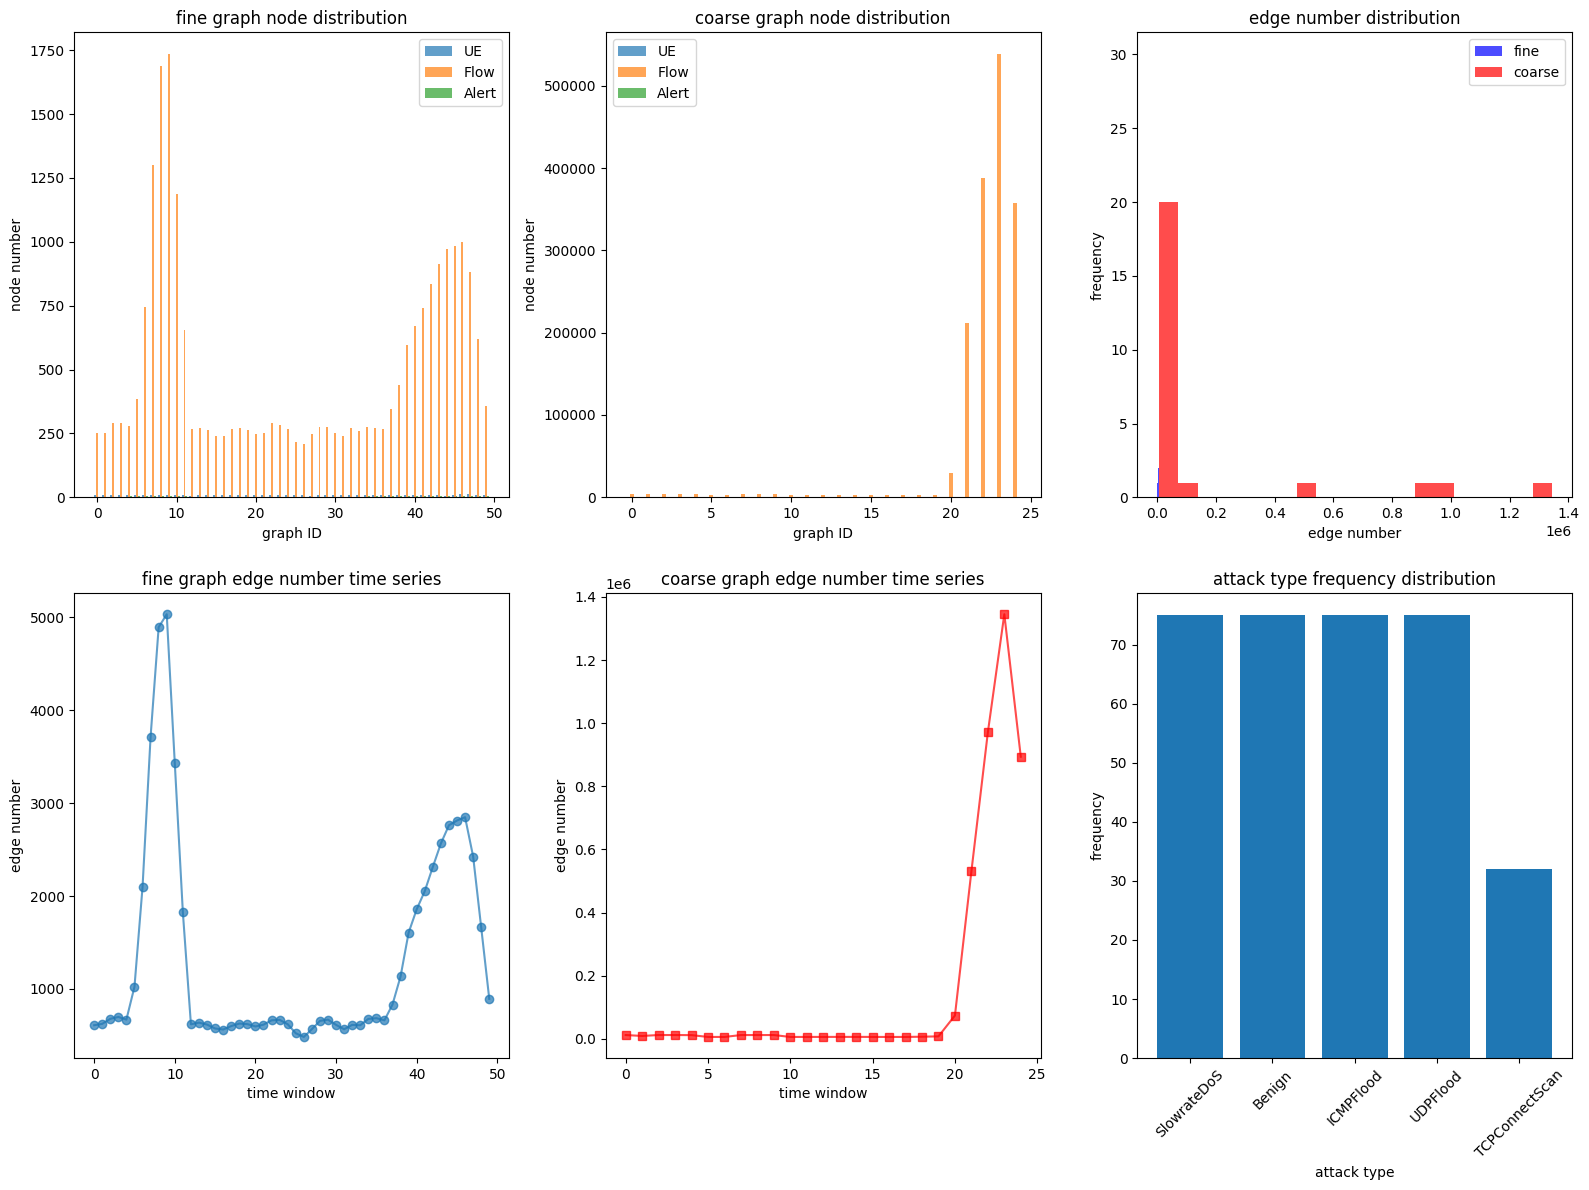

✓ 图统计可视化已保存: ../data/processed/metadata/graph_statistics.png


In [8]:
# 可视化图统计信息

if all_graph_stats:
    # 创建可视化图表
    plt.figure(figsize=(16, 12))
    
    # 1. 节点数量分布 (细粒度)
    plt.subplot(2, 3, 1)
    if fine_stats:
        ue_nodes = [s['num_ue_nodes'] for s in fine_stats]
        flow_nodes = [s['num_flow_nodes'] for s in fine_stats]
        alert_nodes = [s['num_alert_nodes'] for s in fine_stats]
        
        x = np.arange(len(fine_stats))
        width = 0.25
        
        plt.bar(x - width, ue_nodes, width, label='UE', alpha=0.7)
        plt.bar(x, flow_nodes, width, label='Flow', alpha=0.7)
        plt.bar(x + width, alert_nodes, width, label='Alert', alpha=0.7)
        
        plt.title('fine graph node distribution')
        plt.xlabel('graph ID')
        plt.ylabel('node number')
        plt.legend()
    
    # 2. 节点数量分布 (粗粒度)
    plt.subplot(2, 3, 2)
    if coarse_stats:
        ue_nodes = [s['num_ue_nodes'] for s in coarse_stats]
        flow_nodes = [s['num_flow_nodes'] for s in coarse_stats]
        alert_nodes = [s['num_alert_nodes'] for s in coarse_stats]
        
        x = np.arange(len(coarse_stats))
        width = 0.25
        
        plt.bar(x - width, ue_nodes, width, label='UE', alpha=0.7)
        plt.bar(x, flow_nodes, width, label='Flow', alpha=0.7)
        plt.bar(x + width, alert_nodes, width, label='Alert', alpha=0.7)
        
        plt.title('coarse graph node distribution')
        plt.xlabel('graph ID')
        plt.ylabel('node number')
        plt.legend()
    
    # 3. 边数量分布对比
    plt.subplot(2, 3, 3)
    if fine_stats and coarse_stats:
        fine_edges = [s['num_edges'] for s in fine_stats]
        coarse_edges = [s['num_edges'] for s in coarse_stats]
        
        plt.hist(fine_edges, bins=20, alpha=0.7, label='fine', color='blue')
        plt.hist(coarse_edges, bins=20, alpha=0.7, label='coarse', color='red')
        plt.title('edge number distribution')
        plt.xlabel('edge number')
        plt.ylabel('frequency')
        plt.legend()
    
    # 4. 图规模时间序列 (细粒度)
    plt.subplot(2, 3, 4)
    if fine_stats:
        edge_counts = [s['num_edges'] for s in fine_stats]
        plt.plot(edge_counts, marker='o', alpha=0.7)
        plt.title('fine graph edge number time series')
        plt.xlabel('time window')
        plt.ylabel('edge number')
    
    # 5. 图规模时间序列 (粗粒度)
    plt.subplot(2, 3, 5)
    if coarse_stats:
        edge_counts = [s['num_edges'] for s in coarse_stats]
        plt.plot(edge_counts, marker='s', alpha=0.7, color='red')
        plt.title('coarse graph edge number time series')
        plt.xlabel('time window')
        plt.ylabel('edge number')
    
    # 6. 攻击类型频率
    plt.subplot(2, 3, 6)
    all_attack_types = []
    for stats in fine_stats + coarse_stats:
        all_attack_types.extend(stats['attack_types'])
    
    if all_attack_types:
        from collections import Counter
        attack_counts = Counter(all_attack_types)
        attack_names = list(attack_counts.keys())
        attack_frequencies = list(attack_counts.values())
        
        plt.bar(range(len(attack_names)), attack_frequencies)
        plt.title('attack type frequency distribution')
        plt.xlabel('attack type')
        plt.ylabel('frequency')
        plt.xticks(range(len(attack_names)), attack_names, rotation=45)
    
    plt.tight_layout()
    plt.savefig('../data/processed/metadata/graph_statistics.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ 图统计可视化已保存: ../data/processed/metadata/graph_statistics.png")


In [9]:
# Phase 5 完成总结与Phase 6 准备

# 检查输出文件
graph_files = glob.glob('../data/processed/graphs/hetero_graph_*.dgl')
print(f"\n🎯 Phase 5 完成总结:")
print(f"  ✓ 异质图文件生成: {len(graph_files)} 个")
print(f"  ✓ 数据质量验证: 已完成")
print(f"  ✓ 特征提取优化: 已完成")
print(f"  ✓ 图统计分析: 已完成")

# 为Phase 6提供输出摘要
phase6_input_summary = {
    "graph_files": {
        "location": "../data/processed/graphs/",
        "pattern": "hetero_graph_*.dgl",
        "count": len(graph_files),
        "types": ["fine", "coarse"]
    },
    "graph_structure": {
        "node_types": ["UE", "Flow", "Alert"],
        "edge_types": ["initiates", "triggers", "temporal_adj"],
        "features": {
            "UE": "16维随机特征",
            "Flow": "多维流量特征(标准化)",
            "Alert": "one-hot攻击类型编码"
        }
    },
    "data_access": {
        "load_function": "dgl.load_graphs()",
        "metadata_file": "../data/processed/metadata/graph_statistics.json",
        "recommended_batch_size": "10-20个图文件"
    }
}

# 保存Phase 6输入摘要
with open('../data/processed/metadata/phase6_input_summary.json', 'w', encoding='utf-8') as f:
    json.dump(phase6_input_summary, f, indent=2, ensure_ascii=False)

print(f"\n📋 为Phase 6准备的输入摘要:")
print(f"  - 图文件位置: {phase6_input_summary['graph_files']['location']}")
print(f"  - 图文件数量: {phase6_input_summary['graph_files']['count']}")
print(f"  - 节点类型: {phase6_input_summary['graph_structure']['node_types']}")
print(f"  - 边类型: {phase6_input_summary['graph_structure']['edge_types']}")
print(f"  - Phase 6输入摘要: ../data/processed/metadata/phase6_input_summary.json")

if len(graph_files) > 0:
    print(f"\n✅ Phase 5 异质图构建成功完成!")
    print(f"   可以继续进行 Phase 6: 风险权重映射")
    
    # 显示前几个生成的图文件
    print(f"\n📁 生成的图文件示例:")
    for i, f in enumerate(sorted(graph_files)[:5]):
        file_size = os.path.getsize(f) / 1024  # KB
        print(f"  {i+1}. {os.path.basename(f)} ({file_size:.1f}KB)")
    
    if len(graph_files) > 5:
        print(f"     ... 还有 {len(graph_files)-5} 个文件")
else:
    print(f"\n⚠️ 未生成图文件，请检查前面的处理步骤")

print(f"\n🔄 流程继续: 请运行 06_risk_weight_mapping.ipynb")



🎯 Phase 5 完成总结:
  ✓ 异质图文件生成: 75 个
  ✓ 数据质量验证: 已完成
  ✓ 特征提取优化: 已完成
  ✓ 图统计分析: 已完成

📋 为Phase 6准备的输入摘要:
  - 图文件位置: ../data/processed/graphs/
  - 图文件数量: 75
  - 节点类型: ['UE', 'Flow', 'Alert']
  - 边类型: ['initiates', 'triggers', 'temporal_adj']
  - Phase 6输入摘要: ../data/processed/metadata/phase6_input_summary.json

✅ Phase 5 异质图构建成功完成!
   可以继续进行 Phase 6: 风险权重映射

📁 生成的图文件示例:
  1. hetero_graph_coarse_t1663200000.dgl (516.7KB)
  2. hetero_graph_coarse_t1663200010.dgl (404.1KB)
  3. hetero_graph_coarse_t1663200020.dgl (518.7KB)
  4. hetero_graph_coarse_t1663200030.dgl (517.5KB)
  5. hetero_graph_coarse_t1663200040.dgl (505.0KB)
     ... 还有 70 个文件

🔄 流程继续: 请运行 06_risk_weight_mapping.ipynb
